# Five-crop simulator: held-out evaluation

**Interpretation warning:** synthetic scores only describe simulator reconstruction. Real source records keep their published target; no unrelated studies are joined.

## Data and split
120,000 generated readings = 500 simulated starting lots × 6 storage paths × 40 observations. The final test has 100 starting lots; every path from a lot stays in the same split.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'artifacts').exists(): ROOT=ROOT.parent
ART=ROOT/'artifacts'
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.spines.top':False,'axes.spines.right':False})
status=json.loads((ART/'status_metrics.json').read_text()); m=json.loads((ART/'advanced_status_metrics.json').read_text()); surv=json.loads((ART/'survival_metrics.json').read_text())
print(status['warning']); print('Fixed grouped holdout:',m['combined']['xgboost']['test_lots'],'lots')

SIMULATION ONLY: reconstruction of simulator assumptions, not validated crop accuracy.
Fixed grouped holdout: 100 lots


## Feature-family comparison (same held-out lots)

,Model / input,Macro F1,Spoiled recall,Log loss,Brier
0,environment_only / random_forest,0.8226,0.8399,0.4077,0.2553
1,environment_only / xgboost,0.8360,0.8445,0.3921,0.2382
2,mq_only / random_forest,0.9230,0.9526,0.1908,0.1138
3,mq_only / xgboost,0.9251,0.9526,0.1738,0.1084
4,combined / random_forest,0.9309,0.9587,0.1783,0.1055
5,combined / xgboost,0.9300,0.9562,0.1622,0.1004


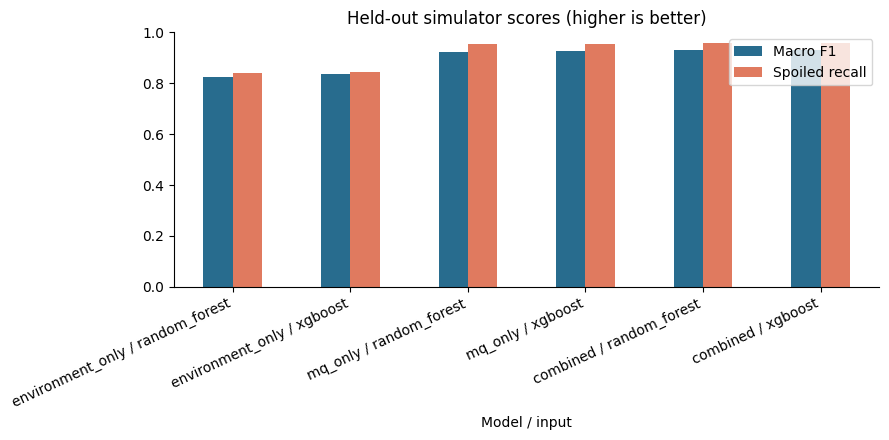

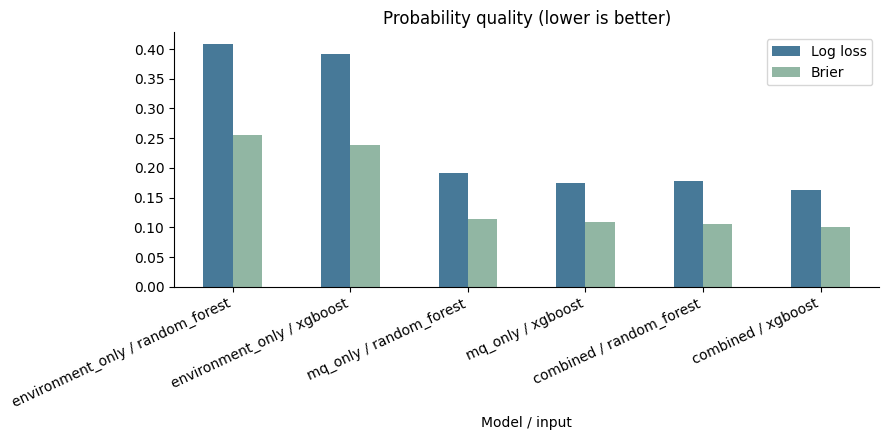

In [2]:
rows=[]
for key,r in m['test_feature_families'].items():
 rows.append({'Model / input':key.replace('__',' / '),'Macro F1':r['macro_f1'],'Spoiled recall':r['per_class']['spoiled']['recall'],'Log loss':r['log_loss'],'Brier':r['multiclass_brier']})
for model,r in m['combined'].items(): rows.append({'Model / input':'combined / '+model,'Macro F1':r['macro_f1'],'Spoiled recall':r['per_class']['spoiled']['recall'],'Log loss':r['log_loss'],'Brier':r['multiclass_brier']})
df=pd.DataFrame(rows); display(df.round(4)); ax=df.set_index('Model / input')[['Macro F1','Spoiled recall']].plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f']); ax.set_title('Held-out simulator scores (higher is better)'); plt.xticks(rotation=25,ha='right'); plt.tight_layout(); plt.show()
ax=df.set_index('Model / input')[['Log loss','Brier']].plot.bar(color=['#477998','#91b6a3']); ax.set_title('Probability quality (lower is better)'); plt.xticks(rotation=25,ha='right'); plt.tight_layout(); plt.show()

## Per-class precision, recall, F1 and confusion matrix — combined XGBoost

,Precision,Recall,F1
acceptable,0.915,0.931,0.923
warning,0.904,0.903,0.904
spoiled,0.971,0.956,0.963


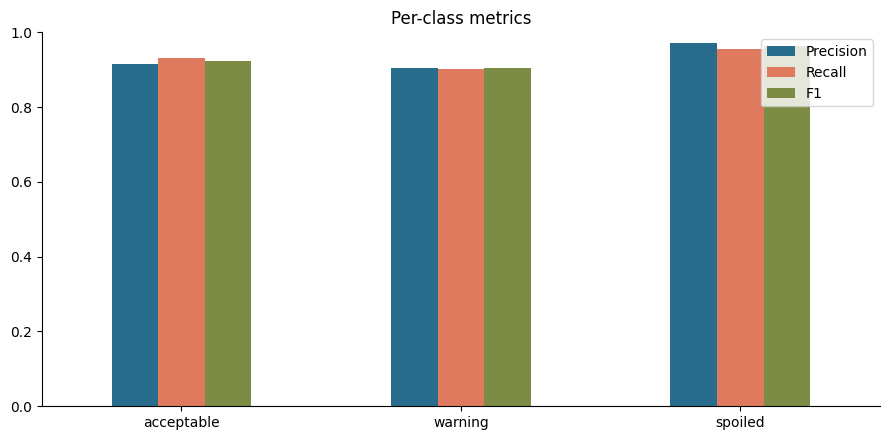

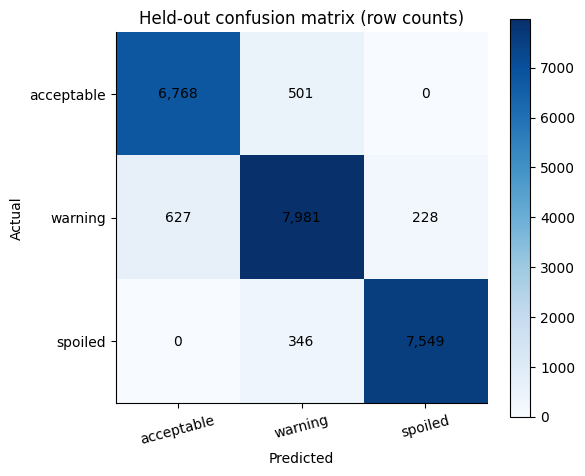

In [3]:
best=m['combined']['xgboost']; labels=best['confusion_matrix_labels_order']; cls=pd.DataFrame({k:{'Precision':best['per_class'][k]['precision'],'Recall':best['per_class'][k]['recall'],'F1':best['per_class'][k]['f1-score']} for k in labels}).T; display(cls.round(3)); cls.plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f','#7d8c45']); plt.title('Per-class metrics'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
cm=np.asarray(best['confusion_matrix']); fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(cm,cmap='Blues'); ax.set_xticks(range(3),labels,rotation=15); ax.set_yticks(range(3),labels); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Held-out confusion matrix (row counts)')
for i in range(3):
 for j in range(3): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center')
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## Crop results and survival
Hazard metrics refer to risk at the next inspection interval. AUC is not days-left accuracy.

,Macro F1,Spoiled recall,Warning recall
crop,,,
maize,0.923,0.939,0.896
onion,0.916,0.939,0.852
potato,0.940,0.962,0.927
spinach,0.951,0.972,0.930
wheat,0.919,0.954,0.910


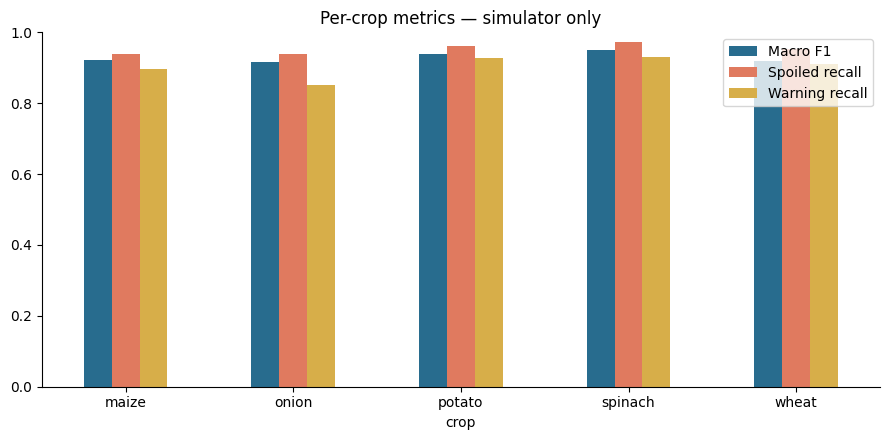

,Brier,AUC
Model,,
logistic,0.0550,0.9830
xgboost,0.0154,0.9804


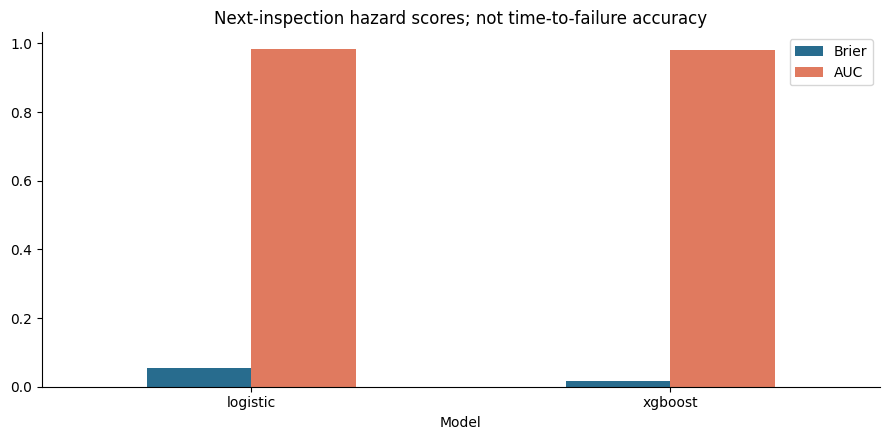

In [4]:
pc=pd.DataFrame([{'crop':c,'Macro F1':r['macro_f1'],'Spoiled recall':r['per_class']['spoiled']['recall'],'Warning recall':r['per_class']['warning']['recall']} for c,r in best['per_crop'].items()]).set_index('crop'); display(pc.round(3)); pc.plot.bar(ylim=(0,1),color=['#286c8e','#e07a5f','#d7ae49']); plt.title('Per-crop metrics — simulator only'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
h=surv['discrete_hazard_all_interval_metrics']; hdf=pd.DataFrame([{'Model':k.replace('discrete_hazard_',''),'Brier':v['all_observed_at_risk_intervals']['brier'],'AUC':v['all_observed_at_risk_intervals']['auc']} for k,v in h.items()]).set_index('Model'); display(hdf.round(4)); hdf.plot.bar(color=['#286c8e','#e07a5f']); plt.title('Next-inspection hazard scores; not time-to-failure accuracy'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()